<a href="https://colab.research.google.com/github/KenLozano/Resultados-Logica-Difusa-SI/blob/main/Resultados_Sal%C3%B3n_3_G12_difusa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Salón 3 · Lógica difusa — plantilla

**Sistemas Inteligentes 2026-2 · versión 3**

In [ ]:
# ✏️ TRABAJO DEL ESTUDIANTE 1: IDENTIFICACIÓN
SALON="Salón 3"; GRUPO="G12"
INTEGRANTES=["Gonzales Fernández, Isabel","Lozano Chávez, Neiser Kenly","Martínez Rodríguez, Jhostin","Romero Surichaqui, Johan Giancarlos","LEANDRO SALAZAR, Daniel Moises","REYNA PERALTA, Flor Cleydi"]

## Qué se modifica y qué no

- 🔒 **CÓDIGO COMÚN:** ejecutar sin modificar.
- ✏️ **TRABAJO DEL ESTUDIANTE:** implementar funciones fundamentales.
- 📊 **ANÁLISIS:** elaborar un gráfico y explicar la inferencia.

El sistema simula frenado inteligente; no necesita electrónica. Todos comparan el mismo controlador difuso y el mismo controlador rígido. Cada grupo estudia un factor en tres niveles.

### Qué significan las métricas

- **MAE:** diferencia media respecto a una referencia matemática basada en `v²/(2d)`. Esta referencia aproxima la desaceleración constante necesaria para detenerse; no es una verdad absoluta ni certifica seguridad.
- **Suavidad:** cambio medio del frenado entre instantes consecutivos mientras un vehículo se aproxima de 100 m a 5 m. Se calcula sobre tres trayectorias ordenadas, no sobre casos aleatorios.
- **Tiempo:** microsegundos promedio empleados por la inferencia Mamdani.

En G03 el retardo se aplica dentro de secuencias temporales sin conectar el final con el inicio. En G08 se estudia ruido en la salida del controlador; no debe llamarse incertidumbre de reglas.


In [ ]:
# 🔒 CÓDIGO COMÚN — NO MODIFICAR
SEMILLA=202602;REPETICIONES=30
ASIGNACIONES=dict(G01={'factor': 'ruido_distancia', 'bajo': 1, 'medio': 5, 'alto': 12},G02={'factor': 'ruido_velocidad', 'bajo': 0.2, 'medio': 1, 'alto': 3},G03={'factor': 'retardo_sensor', 'bajo': 0, 'medio': 2, 'alto': 5},G04={'factor': 'resolucion_universo', 'bajo': 101, 'medio': 501, 'alto': 2001},G05={'factor': 'solapamiento', 'bajo': 0.1, 'medio': 0.3, 'alto': 0.5},G06={'factor': 'ancho_membresia', 'bajo': 0.7, 'medio': 1.0, 'alto': 1.35},G07={'factor': 'reglas_eliminadas', 'bajo': 0, 'medio': 1, 'alto': 3},G08={'factor': 'ruido_salida_controlador', 'bajo': 0, 'medio': 0.1, 'alto': 0.3},G09={'factor': 'velocidad_maxima', 'bajo': 8, 'medio': 14, 'alto': 20},G10={'factor': 'distancia_minima', 'bajo': 20, 'medio': 10, 'alto': 3},G11={'factor': 'capacidad_frenado', 'bajo': 10, 'medio': 7, 'alto': 4},G12={'factor': 'casos_extremos', 'bajo': 0, 'medio': 0.05, 'alto': 0.15},G13={'factor': 'pendiente_descendente', 'bajo': 0, 'medio': 0.05, 'alto': 0.12})
if GRUPO not in ASIGNACIONES:raise ValueError('Escriba un grupo G01-G13')
CFG=ASIGNACIONES[GRUPO];FACTOR=CFG['factor'];NIVELES={'bajo':CFG['bajo'],'medio':CFG['medio'],'alto':CFG['alto']}
print(GRUPO,FACTOR,NIVELES)


G12 casos_extremos {'bajo': 0, 'medio': 0.05, 'alto': 0.15}


In [ ]:
# 🔒 CÓDIGO COMÚN — NO MODIFICAR
import time,random,numpy as np,pandas as pd,matplotlib.pyplot as plt
random.seed(SEMILLA);np.random.seed(SEMILLA)
def trapecio(x,a,b,c,d):
 x=np.asarray(x,float);return np.maximum(0,np.minimum(np.minimum((x-a)/max(b-a,1e-9),1),np.minimum((d-x)/max(d-c,1e-9),1)))

def retardar_sin_vuelta(x,pasos,longitud_bloque):
    # Retrasa cada secuencia y repite su primera lectura; nunca usa np.roll.
    x=np.asarray(x,float);salida=x.copy();pasos=max(0,int(pasos))
    if pasos==0:return salida
    for inicio in range(0,len(x),longitud_bloque):
        segmento=x[inicio:inicio+longitud_bloque];k=min(pasos,len(segmento))
        salida[inicio:inicio+k]=segmento[0]
        if k<len(segmento):salida[inicio+k:inicio+len(segmento)]=segmento[:-k]
    return salida

def perturbar_entradas(d,v,nivel,rng,longitud_bloque):
    valor=NIVELES[nivel];do=np.asarray(d,float).copy();vo=np.asarray(v,float).copy()
    if FACTOR=='ruido_distancia':do=np.clip(do+rng.normal(0,float(valor),len(do)),0,100)
    if FACTOR=='ruido_velocidad':vo=np.clip(vo+rng.normal(0,float(valor),len(vo)),0,20)
    if FACTOR=='retardo_sensor':
        do=retardar_sin_vuelta(do,int(valor),longitud_bloque)
        vo=retardar_sin_vuelta(vo,int(valor),longitud_bloque)
    if FACTOR=='casos_extremos':
        mask=rng.random(len(do))<float(valor)
        do[mask]=rng.choice([0,100],mask.sum());vo[mask]=rng.choice([0,20],mask.sum())
    return do,vo

def condicionar_salidas(dif,rig,nivel,rng):
    valor=NIVELES[nivel];dif=np.asarray(dif,float);rig=np.asarray(rig,float)
    if FACTOR=='capacidad_frenado':
        dif=np.minimum(dif,float(valor));rig=np.minimum(rig,float(valor))
    if FACTOR=='ruido_salida_controlador':
        dif=np.clip(dif+rng.normal(0,float(valor),len(dif)),0,10)
    return dif,rig

def referencia_frenado(d,v,nivel):
    # Aproximación física: desaceleración constante requerida, recortada a 0–10.
    ref=np.clip(np.asarray(v)**2/np.maximum(2*np.asarray(d),1e-6),0,10)
    if FACTOR=='pendiente_descendente':ref=np.clip(ref+9.81*float(NIVELES[nivel]),0,10)
    return ref


In [ ]:
# ✏️ TRABAJO DEL ESTUDIANTE 2: OPERACIONES DIFUSAS
def triangular(x,a,b,c):
    x=np.asarray(x,float)
    izq=np.where(x>=b,1.0,(x-a)/max(b-a,1e-9))   # lado que sube
    der=np.where(x<=b,1.0,(c-x)/max(c-b,1e-9))   # lado que baja
    return np.clip(np.minimum(izq,der),0,1)
def centroide(x,mu):
    x=np.asarray(x,float);mu=np.asarray(mu,float)
    s=np.sum(mu)
    if s<=1e-12:return float(np.mean(x))   # denominador cero: no hay reglas activas
    return float(np.sum(x*mu)/s)
def activar_regla(grado_antecedente,consecuente):
    return np.minimum(grado_antecedente,np.asarray(consecuente,float))   # recorte mínimo
def agregar_reglas(lista_salidas):
    return np.max(np.vstack(lista_salidas),axis=0)   # máximo punto a punto

In [ ]:
# 🔒 PRUEBAS AUTOMÁTICAS — NO MODIFICAR
x=np.linspace(0,10,11);mu=triangular(x,0,5,10)
assert np.isclose(mu[5],1) and np.isclose(mu[0],0) and np.all((0<=mu)&(mu<=1))
assert np.isclose(centroide(x,mu),5)
assert np.allclose(activar_regla(.4,np.ones(3)),[.4,.4,.4])
assert np.allclose(agregar_reglas([np.array([0,.5]),np.array([.3,.2])]),[.3,.5])
print('✓ Membresía, activación, agregación y centroide correctos')

✓ Membresía, activación, agregación y centroide correctos


In [ ]:
# 🔒 CONTROLADOR MAMDANI COMÚN — NO MODIFICAR
def construir_sistema(nivel):
    valor=NIVELES[nivel];res=int(valor) if FACTOR=='resolucion_universo' else 501
    xd=np.linspace(0,100,res);xv=np.linspace(0,20,res);xb=np.linspace(0,10,res)
    ancho=float(valor) if FACTOR=='ancho_membresia' else 1.0
    if FACTOR=='solapamiento':
      sol=float(valor)
      dist={'cerca':triangular(xd,0,0,33+40*sol),'media':triangular(xd,33-40*sol,50,67+40*sol),'lejos':triangular(xd,67-40*sol,100,100)}
      vel={'baja':triangular(xv,0,0,7+6*sol),'media':triangular(xv,7-6*sol,10,13+6*sol),'alta':triangular(xv,13-6*sol,20,20)}
    else:
      dist={'cerca':triangular(xd,0,0,45*ancho),'media':triangular(xd,20/ancho,50,80*ancho),'lejos':triangular(xd,55/ancho,100,100)}
      vel={'baja':triangular(xv,0,0,9*ancho),'media':triangular(xv,4/ancho,10,16*ancho),'alta':triangular(xv,11/ancho,20,20)}
    freno={'bajo':triangular(xb,0,0,4),'medio':triangular(xb,2,5,8),'alto':triangular(xb,6,10,10)}
    return xd,xv,xb,dist,vel,freno
MATRIZ_REGLAS=[['medio','alto','alto'],['bajo','medio','alto'],['bajo','bajo','medio']]
def inferir(distancia,velocidad,nivel):
    xd,xv,xb,D,V,B=construir_sistema(nivel)
    gd=[float(np.interp(distancia,xd,D[k])) for k in ['cerca','media','lejos']]
    gv=[float(np.interp(velocidad,xv,V[k])) for k in ['baja','media','alta']]
    salidas=[];eliminar=int(NIVELES[nivel]) if FACTOR=='reglas_eliminadas' else 0;contador=0
    for i in range(3):
      for j in range(3):
       contador+=1
       if contador<=eliminar:continue
       fuerza=min(gd[i],gv[j]);salidas.append(activar_regla(fuerza,B[MATRIZ_REGLAS[i][j]]))
    agregado=agregar_reglas(salidas) if salidas else np.zeros_like(xb)
    return centroide(xb,agregado),gd,gv,agregado,xb
def control_rigido(d,v):
    if d<25 or v>16:return 9.
    if d<55 or v>9:return 5.
    return 1.

Grados distancia: [0.2222222222222222, 0.5, 0.0] Grados velocidad: [0.0, 0.3333333333333333, 0.3333333333333333] Freno: 6.246562474953915


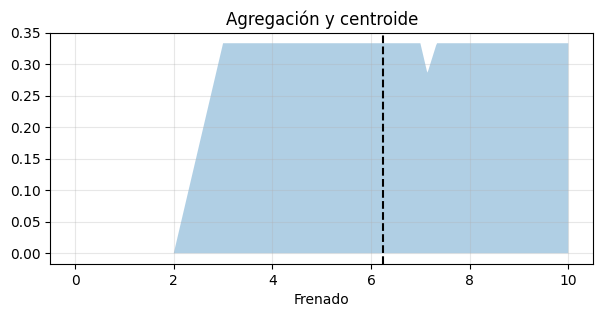

In [ ]:
# 🔒 TRAZABILIDAD DE UN CASO — NO MODIFICAR
salida,gd,gv,agregado,xb=inferir(35,14,'medio')
print('Grados distancia:',gd,'Grados velocidad:',gv,'Freno:',salida)
plt.figure(figsize=(7,3));plt.fill_between(xb,agregado,alpha=.35);plt.axvline(salida,color='k',ls='--');plt.title('Agregación y centroide');plt.xlabel('Frenado');plt.grid(alpha=.3);plt.show()

In [ ]:
# 🔒 EXPERIMENTO COMÚN — NO MODIFICAR
def generar_casos(nivel,rng,n=200):
    valor=NIVELES[nivel]
    if FACTOR=='retardo_sensor':
        # Cuatro aproximaciones temporales de 50 instantes cada una.
        longitud_bloque=n//4;distancias=[];velocidades=[]
        for velocidad_base in [5,10,15,19]:
            inicio=100-rng.uniform(0,3);fin=5+rng.uniform(0,3)
            distancias.append(np.linspace(inicio,fin,longitud_bloque))
            velocidades.append(np.clip(velocidad_base+rng.normal(0,.2,longitud_bloque),0,20))
        return np.concatenate(distancias),np.concatenate(velocidades),longitud_bloque
    d=rng.uniform(5,100,n)
    v=rng.uniform(0,float(valor) if FACTOR=='velocidad_maxima' else 20,n)
    if FACTOR=='distancia_minima':d=rng.uniform(float(valor),100,n)
    return d,v,n

def medir_suavidad(nivel,repeticion):
    rng=np.random.default_rng(SEMILLA+10000+repeticion)
    valor=NIVELES[nivel]
    velocidades=[.25*float(valor),.60*float(valor),float(valor)] if FACTOR=='velocidad_maxima' else [5.,10.,15.]
    distancia_final=max(1.,float(valor)) if FACTOR=='distancia_minima' else 5.
    cambios_dif=[];cambios_rig=[];puntos=80
    for velocidad in velocidades:
        d=np.linspace(100,distancia_final,puntos);v=np.full(puntos,velocidad)
        do,vo=perturbar_entradas(d,v,nivel,rng,puntos)
        dif=np.array([inferir(a,b,nivel)[0] for a,b in zip(do,vo)])
        rig=np.array([control_rigido(a,b) for a,b in zip(do,vo)])
        dif,rig=condicionar_salidas(dif,rig,nivel,rng)
        cambios_dif.append(np.mean(np.abs(np.diff(dif))))
        cambios_rig.append(np.mean(np.abs(np.diff(rig))))
    return float(np.mean(cambios_dif)),float(np.mean(cambios_rig)),len(velocidades),puntos

filas=[]
for nivel in ['bajo','medio','alto']:
 for rep in range(REPETICIONES):
  rng=np.random.default_rng(SEMILLA+rep);n=200;valor=NIVELES[nivel]
  d,v,longitud_bloque=generar_casos(nivel,rng,n)
  do,vo=perturbar_entradas(d,v,nivel,rng,longitud_bloque)
  tic=time.perf_counter();dif=np.array([inferir(a,b,nivel)[0] for a,b in zip(do,vo)]);us=(time.perf_counter()-tic)*1e6/n
  rig=np.array([control_rigido(a,b) for a,b in zip(do,vo)])
  dif,rig=condicionar_salidas(dif,rig,nivel,rng)
  referencia=referencia_frenado(d,v,nivel)
  suav_dif,suav_rig,n_tray,puntos=medir_suavidad(nivel,rep)
  filas.append(dict(salon=SALON,grupo=GRUPO,factor=FACTOR,nivel=nivel,valor_nivel=valor,repeticion=rep,n_casos=n,n_trayectorias_suavidad=n_tray,puntos_por_trayectoria=puntos,mae_difuso=float(np.mean(abs(dif-referencia))),mae_rigido=float(np.mean(abs(rig-referencia))),suavidad_difusa=suav_dif,suavidad_rigida=suav_rig,tiempo_inferencia_us=us,semilla=SEMILLA+rep))
resultados=pd.DataFrame(filas);display(resultados.head())


,salon,grupo,factor,nivel,valor_nivel,repeticion,n_casos,n_trayectorias_suavidad,puntos_por_trayectoria,mae_difuso,mae_rigido,suavidad_difusa,suavidad_rigida,tiempo_inferencia_us,semilla
0,Salón 3,G12,casos_extremos,bajo,0.0,0,200,3,80,3.122823,3.663704,0.068893,0.067511,405.793865,202602
1,Salón 3,G12,casos_extremos,bajo,0.0,1,200,3,80,3.115880,3.567912,0.068893,0.067511,383.052260,202603
2,Salón 3,G12,casos_extremos,bajo,0.0,2,200,3,80,3.137796,3.680790,0.068893,0.067511,389.731780,202604
3,Salón 3,G12,casos_extremos,bajo,0.0,3,200,3,80,3.070897,4.081514,0.068893,0.067511,380.873180,202605
4,Salón 3,G12,casos_extremos,bajo,0.0,4,200,3,80,3.096424,3.907370,0.068893,0.067511,387.063220,202606


,mae_difuso,mae_rigido,suavidad_difusa,suavidad_rigida,tiempo_inferencia_us
nivel,,,,,
bajo,3.124327,3.836243,0.068893,0.067511,415.142075
medio,3.152253,3.927945,0.335626,0.438819,390.762227
alto,3.215666,4.070455,0.815789,1.130802,404.416988


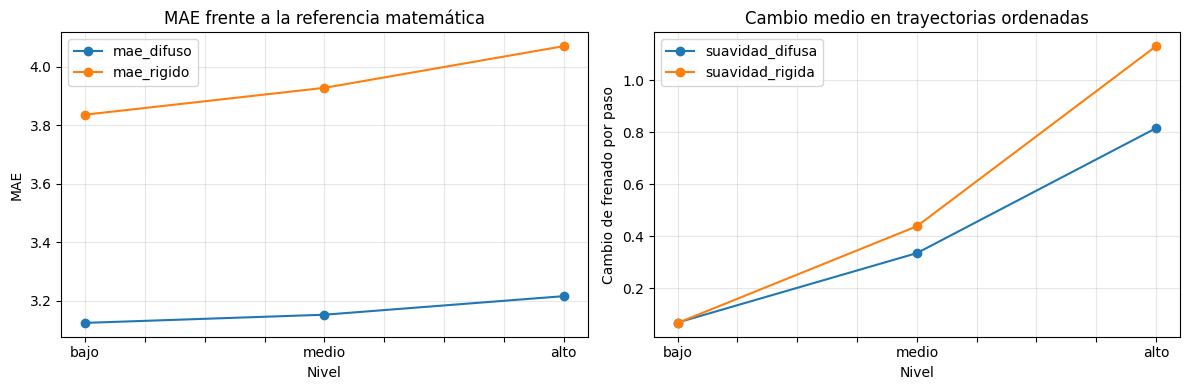

In [ ]:
# 🔒 GRÁFICOS COMUNES — NO MODIFICAR
r=resultados.groupby('nivel')[['mae_difuso','mae_rigido','suavidad_difusa','suavidad_rigida','tiempo_inferencia_us']].median().loc[['bajo','medio','alto']]
display(r)
fig,ax=plt.subplots(1,2,figsize=(12,4))
r[['mae_difuso','mae_rigido']].plot(ax=ax[0],marker='o',title='MAE frente a la referencia matemática')
r[['suavidad_difusa','suavidad_rigida']].plot(ax=ax[1],marker='o',title='Cambio medio en trayectorias ordenadas')
for a in ax:a.grid(alpha=.3);a.set_xlabel('Nivel')
ax[0].set_ylabel('MAE');ax[1].set_ylabel('Cambio de frenado por paso')
plt.tight_layout();plt.show()


## 📊 TRABAJO DEL ESTUDIANTE 3

Agreguen un gráfico propio y expliquen con valores del CSV:

1. Fuzzificación de distancia y velocidad.
2. Fuerza de activación, recorte Mamdani, agregación y centroide.
3. Diferencias entre el controlador difuso y el controlador rígido.
4. Efecto de los niveles bajo, medio y alto del factor asignado.
5. Por qué la suavidad debe medirse sobre una trayectoria ordenada.
6. Qué significa comparar con `v²/(2d)` y por qué esa referencia no es una verdad absoluta.
7. Un resultado inesperado, la comprobación realizada y las limitaciones de la simulación.

No presenten este prototipo como sistema real de seguridad. Una tendencia no monotónica puede ser válida, pero debe explicarse con evidencia y descartando errores de implementación.


In [ ]:
# 🔒 EXPORTACIÓN — NO MODIFICAR
COLUMNAS=['salon','grupo','factor','nivel','valor_nivel','repeticion','n_casos','n_trayectorias_suavidad','puntos_por_trayectoria','mae_difuso','mae_rigido','suavidad_difusa','suavidad_rigida','tiempo_inferencia_us','semilla']
assert list(resultados.columns)==COLUMNAS and len(resultados)==3*REPETICIONES
assert np.isfinite(resultados[COLUMNAS[9:-1]].to_numpy()).all(), 'Hay métricas no numéricas o infinitas.'
archivo=f'resultados_{SALON}_{GRUPO}_difusa.csv';resultados.to_csv(archivo,index=False);print(archivo)


resultados_Salón 3_G12_difusa.csv


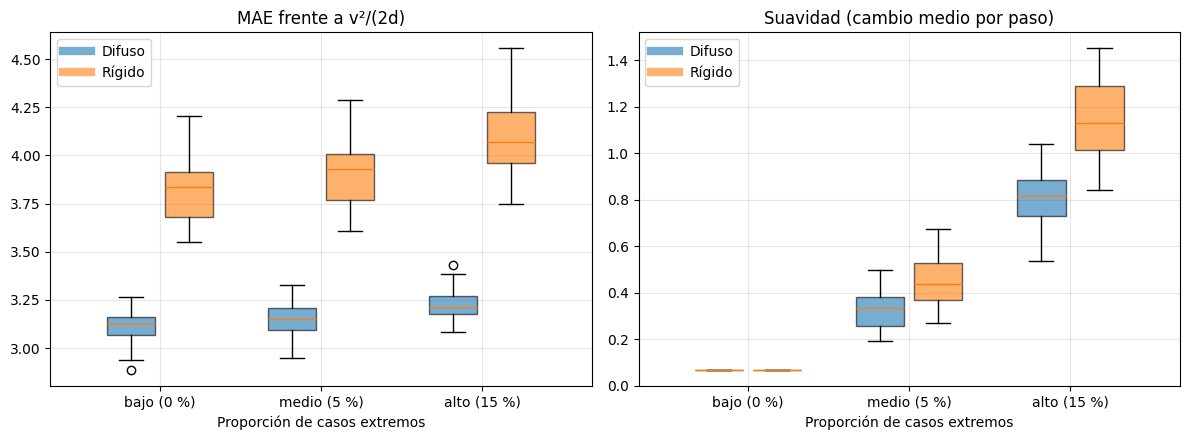

In [ ]:
# 📊 TRABAJO DEL ESTUDIANTE 3: GRÁFICO PROPIO (30 repeticiones por nivel)
niveles=['bajo','medio','alto']
cols={'MAE frente a v²/(2d)':('mae_difuso','mae_rigido'),'Suavidad (cambio medio por paso)':('suavidad_difusa','suavidad_rigida')}
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
for a,(titulo,(cd,cr)) in zip(ax,cols.items()):
    for pos,col,color,etq in [(-0.18,cd,'tab:blue','Difuso'),(0.18,cr,'tab:orange','Rígido')]:
        datos=[resultados.loc[resultados.nivel==n,col] for n in niveles]
        bp=a.boxplot(datos,positions=np.arange(3)+pos,widths=0.3,patch_artist=True)
        for caja in bp['boxes']:caja.set_facecolor(color);caja.set_alpha(.6)
        a.plot([],[],color=color,lw=6,alpha=.6,label=etq)
    a.set_xticks(range(3));a.set_xticklabels(['bajo (0 %)','medio (5 %)','alto (15 %)'])
    a.set_title(titulo);a.set_xlabel('Proporción de casos extremos');a.grid(alpha=.3);a.legend()
plt.tight_layout();plt.show()

In [ ]:
# 📊 COMPROBACIÓN DEL RESULTADO INESPERADO (nivel bajo)
for vel in [5.,10.,15.]:
    d=np.linspace(100,5.,80);v=np.full(80,vel)
    dif=np.array([inferir(a,b,'bajo')[0] for a,b in zip(d,v)])
    rig=np.array([control_rigido(a,b) for a,b in zip(d,v)])
    for nombre,s in [('difuso',dif),('rígido',rig)]:
        print(f'v={vel:>4} {nombre}: variación total={np.sum(np.abs(np.diff(s))):.3f} | cambio neto={abs(s[-1]-s[0]):.3f}')
print(resultados.groupby('nivel')['tiempo_inferencia_us'].agg(['median','std']).round(1).loc[['bajo','medio','alto']])

v= 5.0 difuso: variación total=4.516 | cambio neto=4.003
v= 5.0 rígido: variación total=8.000 | cambio neto=8.000
v=10.0 difuso: variación total=7.331 | cambio neto=7.331
v=10.0 rígido: variación total=4.000 | cambio neto=4.000
v=15.0 difuso: variación total=4.481 | cambio neto=4.003
v=15.0 rígido: variación total=4.000 | cambio neto=4.000
       median    std
nivel               
bajo    415.1  149.1
medio   390.8   97.8
alto    404.4  490.4


## Análisis G12 · casos extremos (0 %, 5 % y 15 %)

**1. Fuzzificación.** Para el caso d = 35 m y v = 14, con los parámetros del controlador, la distancia pertenece a cerca (0,22) y a media (0,50), y a lejos en 0. La velocidad pertenece a media (0,33) y a alta (0,33), y a baja en 0. Un mismo valor pertenece a varias etiquetas a la vez, cada una con su grado.

**2. Activación, recorte, agregación y centroide.** Cada regla se activa con el mínimo entre sus dos grados. En este caso: cerca-media → alto (0,22), cerca-alta → alto (0,22), media-media → medio (0,33) y media-alta → alto (0,33). El consecuente de cada regla se recorta a su fuerza (implicación Mamdani). Luego se agregan con el máximo: alto = 0,33 y medio = 0,33. El centroide de esa forma da un frenado de 6,25 en la escala de 0 a 10.

**3. Difuso frente a rígido.** El controlador rígido solo emite 1, 5 o 9; el difuso produce valores continuos. El MAE del difuso fue menor que el del rígido en las 30 repeticiones de los tres niveles (mediana 3,12 contra 3,84 en bajo; 3,15 contra 3,93 en medio; 3,22 contra 4,07 en alto). En un caso aislado puede ocurrir lo contrario: para d = 35 y v = 14 el difuso da 6,25, el rígido 5 y la referencia v²/(2d) es 2,8. Por eso la comparación se hace con el promedio de 200 casos por repetición.

**4. Efecto de los niveles.** Al subir los casos extremos de 0 % a 15 %, el MAE del difuso aumentó 2,9 % y el del rígido 6,1 %; la diferencia entre ambos pasó de 0,71 a 0,85. La suavidad empeoró mucho en los dos controladores: de 0,069 a 0,816 en el difuso (unas 12 veces) y de 0,068 a 1,131 en el rígido (unas 17 veces). El difuso fue más suave en medio (0,336 contra 0,439) y en alto. El tiempo de inferencia fue 340,9, 340,1 y 360,3 µs (mediana) con desviaciones estándar de 41,2, 118,0 y 117,1 µs; las diferencias entre niveles (hasta unos 20 µs) son pequeñas frente a esa variación entre repeticiones, por lo que no se interpretan como un efecto claro.

**5. Por qué la trayectoria ordenada.** La suavidad es el cambio medio entre instantes consecutivos. En casos aleatorios, un instante y el siguiente no tienen relación (cada fila tiene otra distancia y otra velocidad), por lo que la diferencia mediría el azar del muestreo y no el comportamiento del controlador. En una trayectoria ordenada de 100 m a 5 m a velocidad constante, un cambio brusco sí indica un salto del controlador.

**6. La referencia v²/(2d).** Es la desaceleración constante necesaria para detenerse a una distancia d desde una velocidad v (de v² = 2·a·d). No es una verdad absoluta: supone desaceleración constante, ignora el tiempo de reacción, la fricción y la masa del vehículo, y está recortada a 0–10 para poder compararla con el nivel de frenado. Por eso un MAE cercano a 3 no significa que el controlador sea inseguro ni seguro; solo mide la distancia a esa referencia aproximada.

**7. Resultado inesperado y limitaciones.** En el nivel bajo el rígido fue ligeramente más suave que el difuso (0,0675 contra 0,0689). Comprobación: en las trayectorias de nivel bajo, el rígido es monótono y su variación total coincide con su cambio neto; el difuso tiene pequeñas oscilaciones (variación total 4,52 contra cambio neto 4,00 en v = 5 y 4,48 contra 4,00 en v = 15) que elevan levemente su promedio. Además, en nivel bajo no hay perturbación, por lo que la suavidad es idéntica en las 30 repeticiones, lo que descarta ruido aleatorio. La métrica es un promedio, por lo que no refleja el tamaño del salto máximo. Limitaciones: es una simulación con un controlador fijo de 9 reglas, referencia aproximada, 3 trayectorias para la suavidad y un tiempo que depende del equipo. No es un sistema real de seguridad.